## **Shallow water equations**

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:

#IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

from the_well.data import WellDataset
from the_well.utils.download import well_download

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# Importing modules from src
from src.datamanager import ROMDataManager, DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model
from helpers import plot_overview_and_availability

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks_results/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [3]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
#well_download(base_path="", dataset="planetswe", split="train", first_only=True)

# LOAD THE DATASET
data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


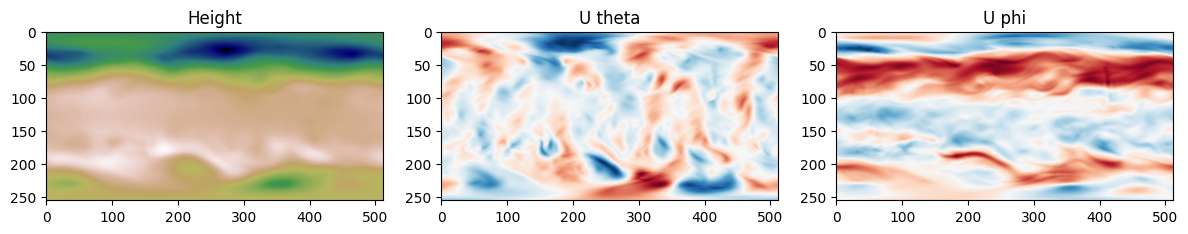

In [4]:
# Define a function to plot the state of the system at a given time step
def plot_state(u, cmap = "RdBu_r"):
    fig = plt.imshow(u.reshape(Lx, Ly), cmap = cmap)

plot_height = lambda u: plot_state(u, cmap = "gist_earth")
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

# Plot the state of the system at the first time step
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plot_height(H[0])
plt.title("Height")
plt.subplot(1, 3, 2)
plot_velocity(Utheta[0])
plt.title("U theta")
plt.subplot(1, 3, 3)        
plot_velocity(Uphi[0])
plt.title("U phi")
plt.tight_layout()
plt.show()

## SENSOR extraction

In [5]:
# EXTRACT SENSORS DATA 

# We randomly select 10 sensors on the grid and extract their time series data from the height field H. 
nsensors = 10
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T
sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

# BROKEN SENSORS SIMULATION
# short broken : random Bernoulli drops
# long broken  : contiguous outage interval

short_broken = 4   # number of sensors with random drops
long_broken  = 4   # number of sensors with a contiguous outage

# Assign which sensors are broken (first short_broken sensors → random drops,
# next long_broken sensors → long outage)
idx_short_broken_s = np.arange(0, short_broken)
idx_long_broken_s  = np.arange(short_broken, short_broken + long_broken)

# Work on a float copy so NaN can be written
sensors_data = sensors_data.float()

# SHORT BROKEN: Bernoulli mask with probability p_short_broken
p_short_broken = 0.2
for local_idx in idx_short_broken_s:
    broken_mask = torch.rand(sensors_data[:, local_idx].shape) < p_short_broken
    print(f"Short broken sensor {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"{broken_mask.sum().item()} of {ntimes} steps masked")
    sensors_data[:, local_idx][broken_mask] = float('nan')

# LONG BROKEN: contiguous interval
for local_idx in idx_long_broken_s:
    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30:                          # ensure a minimum outage length
        t_end = min(t_start + 38, ntimes - 1)
    print(f"Long broken sensor  {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"steps {t_start} to {t_end} masked")
    sensors_data[t_start:t_end + 1, local_idx] = float('nan')

Sensors coordinates:
 [[ 86 450]
 [ 13 196]
 [109  11]
 [181 254]
 [ 94 367]
 [ 57 277]
 [110  82]
 [ 22 153]
 [ 73  18]
 [  4 141]]
Sensors data shape:	 torch.Size([1008, 10])
Short broken sensor 0 (coord [ 86 450]): 195 of 1008 steps masked
Short broken sensor 1 (coord [ 13 196]): 198 of 1008 steps masked
Short broken sensor 2 (coord [109  11]): 210 of 1008 steps masked
Short broken sensor 3 (coord [181 254]): 179 of 1008 steps masked
Long broken sensor  4 (coord [ 94 367]): steps 325 to 935 masked
Long broken sensor  5 (coord [ 57 277]): steps 467 to 963 masked
Long broken sensor  6 (coord [110  82]): steps 21 to 920 masked
Long broken sensor  7 (coord [ 22 153]): steps 439 to 881 masked


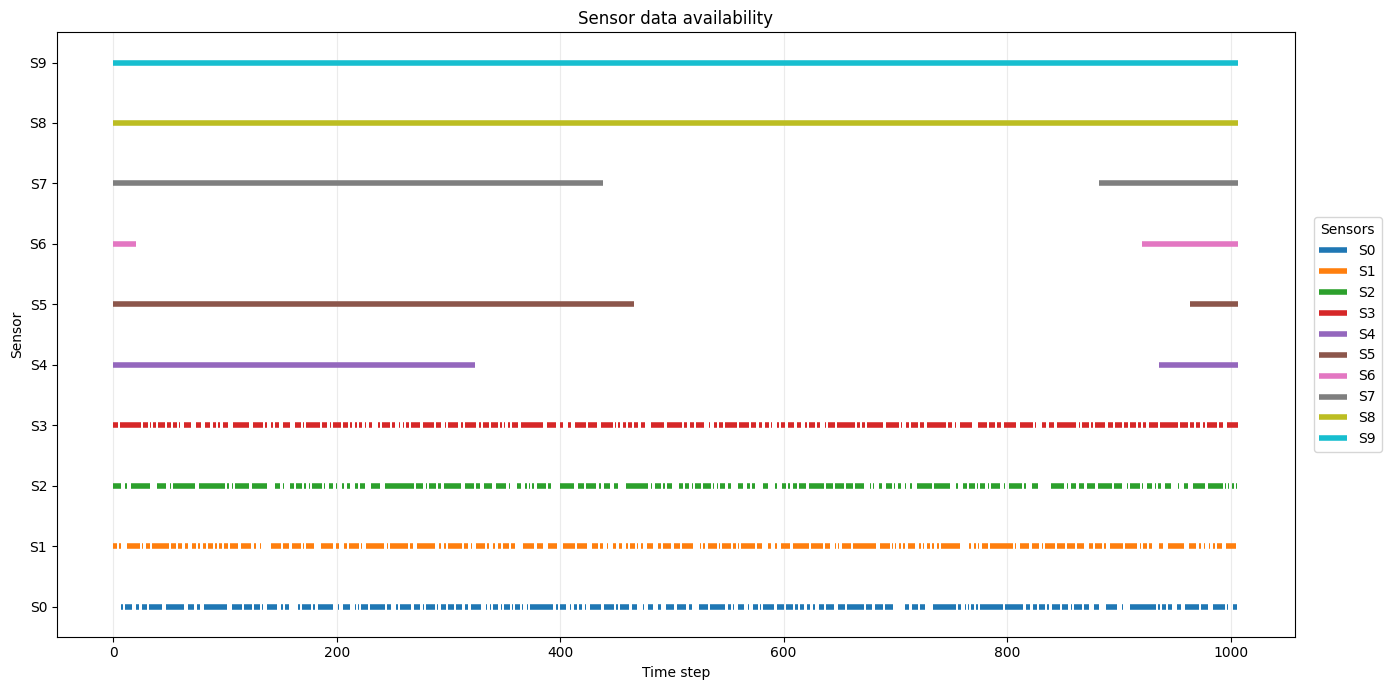

In [6]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, sensor_labels=None):
    """sensor_data: (ntimes, nsensors)"""
    availability = (~torch.isnan(sensor_data)).to(torch.float32).cpu().numpy()
    time          = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    fig_height = max(3.0, 0.7 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(14, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")
    plt.title(title_prefix)
    plt.tight_layout()
    plt.show()

plot_data_availability(sensors_data, "Sensor data availability", sensor_labels=np.arange(nsensors))

## Check -> USE ROM AS IN SHRED ROM

In [7]:
np.random.seed(42)  # For reproducibility

print("Sensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)

H = H.reshape(16, -1, 131072)
sensors_data = sensors_data.reshape(16, -1, 10)

permutation = np.random.permutation(sensors_data.shape[0])
sensors_data = sensors_data[permutation]
H = H[permutation]

print("Sensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)  

del Utheta, Uphi

Sensors data shape:	 torch.Size([1008, 10])
H shape:		 torch.Size([1008, 131072])
Sensors data shape:	 torch.Size([16, 63, 10])
H shape:		 torch.Size([16, 63, 131072])


## Paper image

Sensors on the far side of the sphere (not drawn): ['S0', 'S3', 'S4']


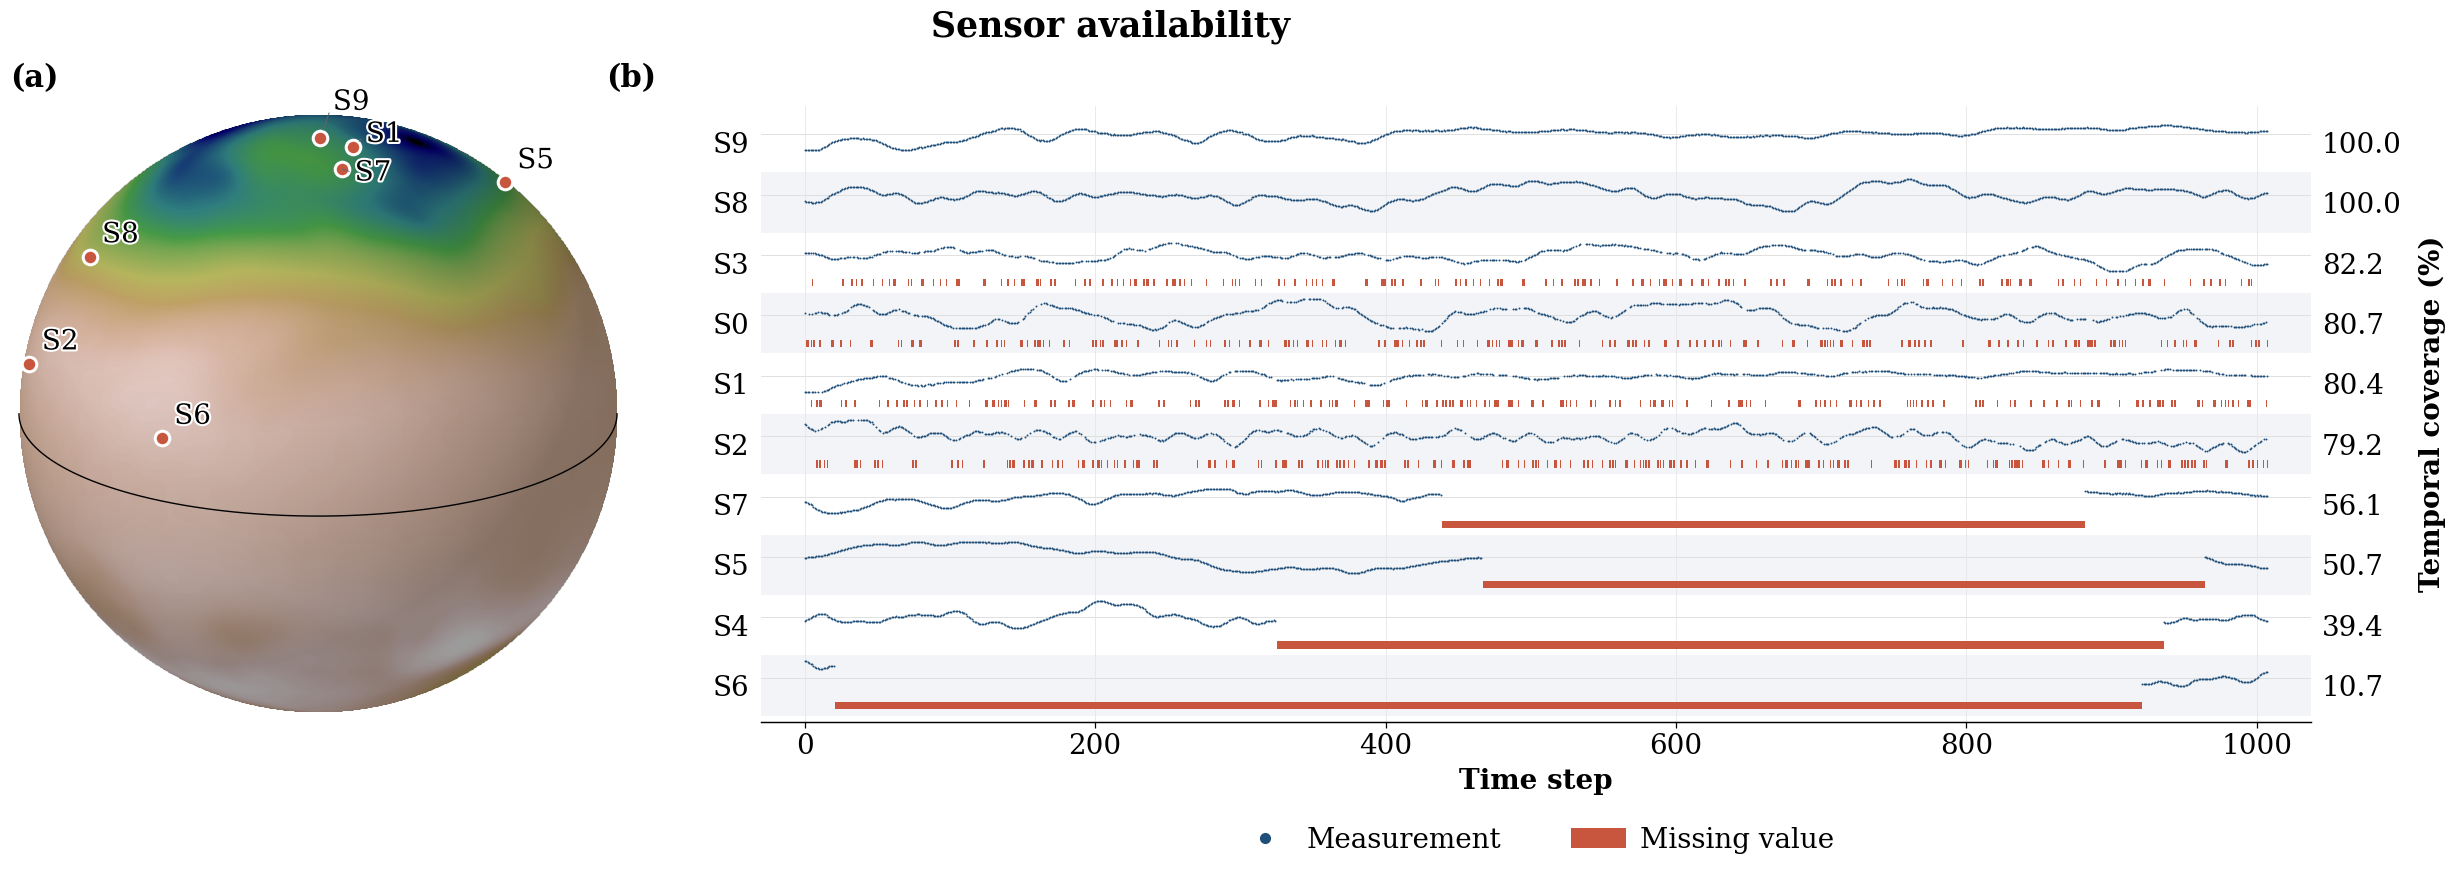

In [9]:
# ==================================================================
# RUN
# ==================================================================
from types import SimpleNamespace


def get_sensor_obs():
    """
    Build the objects needed by the plots from the notebook variables
    (sensors_data, sensors_coordinates, H).

    Cell 10 reshapes + shuffles sensors_data and H into (16, 63, ...) chunks.
    Here the shuffle is undone with `permutation`, so the time axis is the
    original one (0 ... ntimes-1).

    Returns
    -------
    obs_list : list of SimpleNamespace(name, values, x, y)
    H0       : (Lx, Ly) height field at the first time step (map background)
    ntimes   : number of time steps
    """
    sd = sensors_data.detach().cpu().numpy() if hasattr(sensors_data, "detach") else np.asarray(sensors_data)

    if sd.ndim == 3:                                  # cell 10 has been run
        inv = np.argsort(permutation)                 # inverse of the shuffle
        H0 = H[inv[0], 0]                             # first snapshot of the original series
        sd = sd[inv].reshape(-1, sd.shape[-1])        # back to (ntimes, nsensors)
    else:                                             # cell 10 NOT run
        H0 = H[0]

    H0 = H0.detach().cpu().numpy() if hasattr(H0, "detach") else np.asarray(H0)
    H0 = H0.reshape(Lx, Ly)

    obs_list = [
        SimpleNamespace(
            name=f"S{i}",
            values=sd[:, i],
            x=float(sensors_coordinates[i, 1]),       # column index (longitude direction)
            y=float(sensors_coordinates[i, 0]),       # row index (colatitude direction)
        )
        for i in range(sd.shape[1])
    ]
    return obs_list, H0, sd.shape[0]

wllist, H0, ntimes_plot = get_sensor_obs()

fig, axs, cov = plot_overview_and_availability(
    wllist, H0, ntimes_plot,
    figsize=(30, 8),
    font_scale=1.0,
    width_ratios=(0.3, 0.7),
    wspace=0.1,
    panel_labels=True,
    title="Sensor availability",
    elev_deg=20.0,
    azim_deg=90.0,
    savepath="SWE_1_availability.png",
)